## X-Ray Abnormality Detection | ResNet50, pretrained on ImageNet

> **Antonopoulos Ilias** ( *p3352004* ) <br />
> **Ndoja Silva** ( *p3352017* ) <br />
> **MSc in Data Science, AUEB**

## Table of Contents

- [Data Loading](#Data-Loading)
 * [Create a tensorflow input pipeline for the training data](#Create-a-tensorflow-input-pipeline-for-the-training-data)
- [ResNet50 architecture, pretrained on ImageNet](#ResNet50-architecture,-pretrained-on-ImageNet)

In [1]:
import os
import pathlib
import random
import re
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import cohen_kappa_score
from sklearn.utils import shuffle

from utils import (
    clean_up,
    F1Score,
    inspect_df,
    plot_metrics,
)


pd.set_option("max_colwidth", None)
plt.style.use("dark_background")

In [2]:
print(tf.__version__)

2.16.1


In [3]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices("GPU")))

Num GPUs Available:  0


In [4]:
gpus = tf.config.experimental.list_physical_devices("GPU")

try:
    tf.config.experimental.set_memory_growth(gpus[0], True)
except IndexError:
    print("Cannot memory-restrict the GPU, if no GPU exists in system. Ignore...")
    pass

Cannot memory-restrict the GPU, if no GPU exists in system. Ignore...


In [5]:
SEED = 99910123

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
np.random.seed(SEED)

### Data Loading

In [6]:
DATASET_DIR = "../data/MURA-v1.1/"

In [7]:
random.choices(glob(os.path.join(DATASET_DIR, "*", "*", "*", "*", "*.png")), k=10)

['../data/MURA-v1.1\\train\\XR_HAND\\patient10850\\study1_negative\\image1.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient05367\\study1_positive\\image2.png',
 '../data/MURA-v1.1\\valid\\XR_ELBOW\\patient11342\\study1_positive\\image1.png',
 '../data/MURA-v1.1\\train\\XR_HAND\\patient03039\\study1_negative\\image3.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient05051\\study1_positive\\image2.png',
 '../data/MURA-v1.1\\train\\XR_HAND\\patient11016\\study1_negative\\image2.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient05373\\study1_positive\\image2.png',
 '../data/MURA-v1.1\\train\\XR_HAND\\patient10671\\study1_negative\\image1.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient01475\\study1_negative\\image3.png',
 '../data/MURA-v1.1\\train\\XR_HAND\\patient02699\\study1_negative\\image3.png']

So, the data structure is the following:

```

└─train {data subset}
│   └───XR_ELBOW {study type}
│       │  └───patient00011 {patient}
│       │         └───study1_negative {study with label}
│       │               └───image1.png {view}
│       │               └───image2.png 
│       │               └───image3.png 
                        └───...
   ...
   

└─valid {data subset}
│   └───XR_HUMERUS {study type}
│       │  └───patient11216 {patient}
│       │         └───study1_negative {study with label}
│       │               └───image1.png {view}
│       │               └───image2.png 
                        └───...
```

In [8]:
image_count = len(list(pathlib.Path(DATASET_DIR).glob("*/*/*/*/*.png")))

print(f"Total PNG images found in dir <{DATASET_DIR}>: {image_count}")

Total PNG images found in dir <../data/MURA-v1.1/>: 11399


We will start by creating a tabular form of the training data (with no actual image files), in order to quickly analyze them. A proper data loader (of the actual image files) will be implemented after that, in a tensorflow-friendly manner.

In [9]:
train_image_paths = pd.read_csv(
    os.path.join(DATASET_DIR, "train_image_paths.csv"),
    names=["image_path"],
    header=None,
    index_col=False,
)

inspect_df(train_image_paths)

şekil: (36808, 1)


,image_path
0,MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image1.png
1,MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image2.png
2,MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image3.png
3,MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image1.png
4,MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image2.png


In [10]:
train_image_paths["image_path"] = train_image_paths["image_path"].map(
    lambda x: os.path.join("../data/", x)
)
train_image_paths["study_type"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[4]
)
train_image_paths["patient"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[5]
)
train_image_paths["study"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[6]
)
train_image_paths["study_path"] = train_image_paths["image_path"].map(
    lambda x: re.sub(r"image\d+.png", "", x)
)

In [11]:
inspect_df(train_image_paths)

şekil: (36808, 5)


,image_path,study_type,patient,study,study_path
0,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image1.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/
1,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image2.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/
2,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image3.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/
3,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image1.png,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/
4,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image2.png,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/


In [12]:
train_labeled_studies = pd.read_csv(
    os.path.join(DATASET_DIR, "train_labeled_studies.csv"),
    names=["study_path", "label"],
    header=None,
    index_col=False,
)

inspect_df(train_labeled_studies)

şekil: (13457, 2)


,study_path,label
0,MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
1,MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/,1
2,MURA-v1.1/train/XR_SHOULDER/patient00003/study1_positive/,1
3,MURA-v1.1/train/XR_SHOULDER/patient00004/study1_positive/,1
4,MURA-v1.1/train/XR_SHOULDER/patient00005/study1_positive/,1


In [13]:
train_labeled_studies["study_path"] = train_labeled_studies["study_path"].map(
    lambda x: os.path.join("../data/", x)
)
train_labeled_studies["label"] = train_labeled_studies["label"].map(str)

In [14]:
inspect_df(train_labeled_studies)

şekil: (13457, 2)


,study_path,label
0,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
1,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/,1
2,../data/MURA-v1.1/train/XR_SHOULDER/patient00003/study1_positive/,1
3,../data/MURA-v1.1/train/XR_SHOULDER/patient00004/study1_positive/,1
4,../data/MURA-v1.1/train/XR_SHOULDER/patient00005/study1_positive/,1


In [15]:
ref_trainset = pd.merge(
    train_image_paths, train_labeled_studies, how="inner", on="study_path"
)

inspect_df(ref_trainset)

şekil: (36808, 6)


,image_path,study_type,patient,study,study_path,label
0,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image1.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
1,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image2.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
2,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image3.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
3,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image1.png,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/,1
4,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image2.png,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/,1


#### Create a tensorflow input pipeline for the training data

In [16]:
IMAGE_WIDTH = 224
IMAGE_HEIGHT = 224

Since image directory follows a specific ontological structure (7 upper extremities aka study types) we will shuffle the training dataset beforehand in order to ensure that the validation set will be representable of all study types. 

This is due to the fact that tf.keras `tf.keras.preprocessing.image.ImageDataGenerator` first performs the train-val split and then shuffles per epoch by default.

In [17]:
ref_trainset = shuffle(ref_trainset, random_state=SEED)

In [18]:
# tf.keras.applications.resnet50.preprocess_input:
# will convert the input images from RGB to BGR, then will zero-center each color channel
# with respect to the ImageNet dataset, without scaling.
training = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=30,
    horizontal_flip=True,
    fill_mode="constant",
    cval=0.0,
    validation_split=0.2,
    preprocessing_function=tf.keras.applications.resnet50.preprocess_input,
)

In [19]:
trainset = training.flow_from_dataframe(
    dataframe=ref_trainset,
    x_col="image_path",
    y_col="label",
    target_size=(IMAGE_WIDTH, IMAGE_HEIGHT),
    class_mode="binary",
    batch_size=8,
    seed=SEED,
    shuffle=True,
    subset="training",
)

Found 8380 validated image filenames belonging to 2 classes.


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 26334 invalid image filename(s) in x_col="image_path". These filename(s) will be ignored.
  warnings.warn(


In [20]:
validationset = training.flow_from_dataframe(
    dataframe=ref_trainset,
    x_col="image_path",
    y_col="label",
    target_size=(IMAGE_WIDTH, IMAGE_HEIGHT),
    class_mode="binary",
    batch_size=8,
    seed=SEED,
    shuffle=False,
    subset="validation",
)

Found 2094 validated image filenames belonging to 2 classes.


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 26334 invalid image filename(s) in x_col="image_path". These filename(s) will be ignored.
  warnings.warn(


### ResNet50 architecture, pretrained on ImageNet

In [21]:
METRICS = [
    tf.keras.metrics.TruePositives(name="tp"),
    tf.keras.metrics.FalsePositives(name="fp"),
    tf.keras.metrics.TrueNegatives(name="tn"),
    tf.keras.metrics.FalseNegatives(name="fn"),
    tf.keras.metrics.BinaryAccuracy(name="binary_acc"),
    tf.keras.metrics.Precision(name="precision"),
    tf.keras.metrics.Recall(name="recall"),
    F1Score(name="f1_score"),
    tf.keras.metrics.AUC(name="roc_auc", curve="ROC"),
    tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
]

In [22]:
"""
ResNet50 model from `"Deep Residual Learning for Image Recognition" <https://arxiv.org/abs/1512.03385>`_.

We will opt for max pooling for feature extraction, since we want to "emphasize" any sharp features on the image
(e.g hardware placed on human body that most definitely suggests abnormality).
"""
resnet = tf.keras.applications.resnet50.ResNet50(
    include_top=False,  # do not include the fully-connected layer at the top of the network
    weights="imagenet",
    input_shape=(IMAGE_WIDTH, IMAGE_HEIGHT, 3),
    pooling="max",  # pooling mode for feature extraction
    classes=2,
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 108s 1us/step


In [23]:
def make_resnet_model(
    base_model: tf.keras.applications.resnet50.ResNet50,
) -> tf.keras.Model:

    # freeze base model
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(IMAGE_WIDTH, IMAGE_HEIGHT, 3))
    x = base_model(inputs, training=False)
    x = tf.keras.layers.Dropout(rate=0.2)(x)
    output = tf.keras.layers.Dense(units=1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, output)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=METRICS,
    )

    return model

In [24]:
model = make_resnet_model(base_model=resnet)

In [25]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

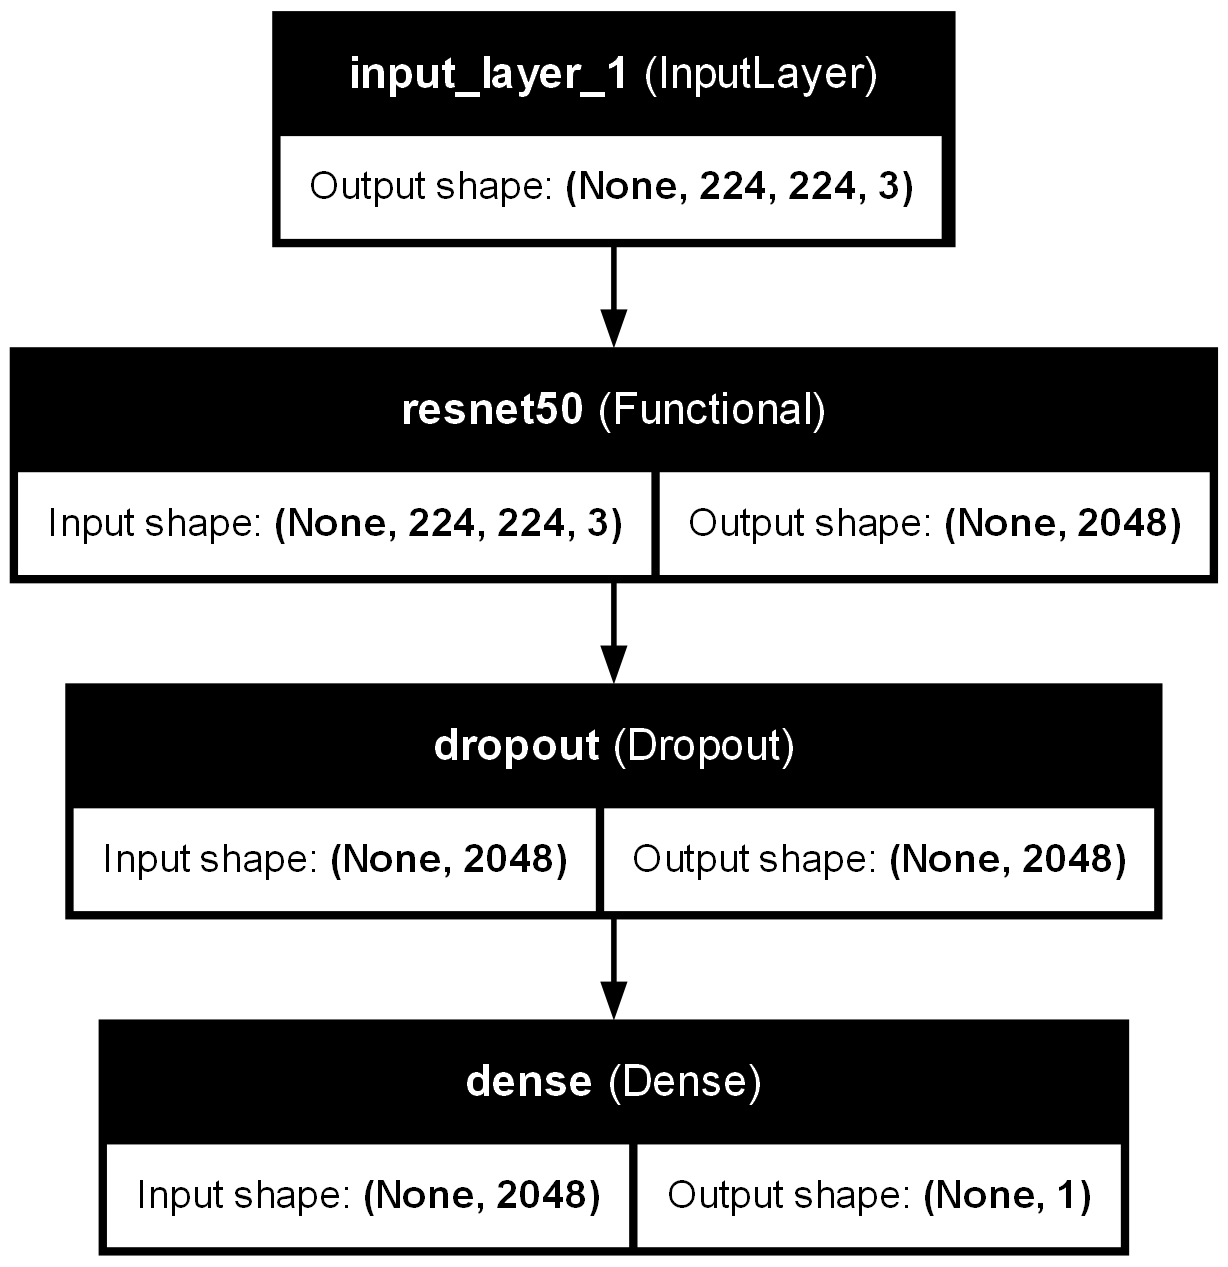

In [26]:
tf.keras.utils.plot_model(
    model,
    to_file=f"../static/resnet50_pt_imagenet-all-study-types-{model.count_params()}.png",
    show_shapes=True,
    show_layer_names=True,
)

In [27]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_cohen_kappa",
    verbose=1,
    patience=5,
    mode="max",
    baseline=0.0,
    restore_best_weights=True,
)

In [28]:
history = model.fit(
    trainset,
    epochs=20,
    validation_data=validationset,
    callbacks=[early_stopping],
)

Epoch 1/20


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1452s 1s/step - binary_acc: 0.5843 - f1_score: 0.3571 - fn: 869.9333 - fp: 855.2898 - loss: 2.2837 - pr_auc: 0.3570 - precision: 0.3622 - recall: 0.3540 - roc_auc: 0.5319 - tn: 1965.7560 - tp: 508.7121 - val_binary_acc: 0.6695 - val_f1_score: 0.3447 - val_fn: 533.0000 - val_fp: 159.0000 - val_loss: 1.2746 - val_pr_auc: 0.4811 - val_precision: 0.5337 - val_recall: 0.2545 - val_roc_auc: 0.6194 - val_tn: 1220.0000 - val_tp: 182.0000
Epoch 2/20


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\callbacks\early_stopping.py:155: UserWarning: Early stopping conditioned on metric `val_cohen_kappa` which is not available. Available metrics are: binary_acc,f1_score,fn,fp,loss,pr_auc,precision,recall,roc_auc,tn,tp,val_binary_acc,val_f1_score,val_fn,val_fp,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc,val_tn,val_tp
  current = self.get_monitor_value(logs)


1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1348s 1s/step - binary_acc: 0.6072 - f1_score: 0.4086 - fn: 823.2822 - fp: 798.3918 - loss: 1.8379 - pr_auc: 0.4091 - precision: 0.4114 - recall: 0.4058 - roc_auc: 0.5809 - tn: 2008.8151 - tp: 569.3775 - val_binary_acc: 0.6910 - val_f1_score: 0.4595 - val_fn: 440.0000 - val_fp: 207.0000 - val_loss: 1.0376 - val_pr_auc: 0.5471 - val_precision: 0.5705 - val_recall: 0.3846 - val_roc_auc: 0.6781 - val_tn: 1172.0000 - val_tp: 275.0000
Epoch 3/20
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1374s 1s/step - binary_acc: 0.6367 - f1_score: 0.4408 - fn: 769.6597 - fp: 728.7693 - loss: 1.5735 - pr_auc: 0.4457 - precision: 0.4496 - recall: 0.4331 - roc_auc: 0.6143 - tn: 2088.7817 - tp: 612.5110 - val_binary_acc: 0.6834 - val_f1_score: 0.5431 - val_fn: 321.0000 - val_fp: 342.0000 - val_loss: 0.9064 - val_pr_auc: 0.5827 - val_precision: 0.5353 - val_recall: 0.5510 - val_roc_auc: 0.7037 - val_tn: 1037.0000 - val_tp: 394.0000
Epoch 4/20
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1406s 1s/step - b

1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1230s 1s/step - binary_acc: 0.7300 - f1_score: 0.5408 - fn: 680.9542 - fp: 456.3365 - loss: 0.5966 - pr_auc: 0.6286 - precision: 0.5956 - recall: 0.4962 - roc_auc: 0.7405 - tn: 2382.4243 - tp: 678.0887 - val_binary_acc: 0.7278 - val_f1_score: 0.3610 - val_fn: 554.0000 - val_fp: 16.0000 - val_loss: 0.7293 - val_pr_auc: 0.7023 - val_precision: 0.9096 - val_recall: 0.2252 - val_roc_auc: 0.7817 - val_tn: 1363.0000 - val_tp: 161.0000
Epoch 19/20
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1232s 1s/step - binary_acc: 0.7357 - f1_score: 0.5651 - fn: 673.9056 - fp: 444.4137 - loss: 0.5905 - pr_auc: 0.6508 - precision: 0.6214 - recall: 0.5186 - roc_auc: 0.7508 - tn: 2362.4919 - tp: 716.7674 - val_binary_acc: 0.7622 - val_f1_score: 0.5473 - val_fn: 414.0000 - val_fp: 84.0000 - val_loss: 0.5314 - val_pr_auc: 0.7050 - val_precision: 0.7818 - val_recall: 0.4210 - val_roc_auc: 0.7755 - val_tn: 1295.0000 - val_tp: 301.0000
Epoch 20/20
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1234s 1s/step - b

In [29]:
# model naming convention: {architecture}-{which-study-type?}-{num-parameters}.h5
#
# to load models:
# model = tf.keras.models.load_model(
#     '../models/resnet50_pt_imagenet-all-study-types-?.h5',
#     custom_objects={'F1Score': F1Score}
# )
# densenet = tf.keras.models.load_model(
#     '../models/resnet50_base.h5',
# )
print(
    f"Saving: ../models/resnet50_pt_imagenet-all-study-types-{model.count_params()}.h5"
)
model.save(f"../models/resnet50_pt_imagenet-all-study-types-{model.count_params()}.h5")
resnet.save("../models/resnet50_base.h5")

Saving: ../models/resnet50_pt_imagenet-all-study-types-23589761.h5


In [30]:
# fine-tuning: unfreeze the base model and train the entire model end-to-end with a low learning rate
resnet.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        1e-5
    ),  # we need small learning rate to avoid catastrophic forgetting
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=METRICS,
)

In [31]:
reduce_lr_on_plateau = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_cohen_kappa",
    verbose=1,
    patience=4,
    mode="max",
    factor=0.2,
    min_lr=1e-10,
)

In [32]:
history = model.fit(
    trainset,
    epochs=10,
    validation_data=validationset,
    callbacks=[early_stopping, reduce_lr_on_plateau],
)

Epoch 1/10
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 4969s 5s/step - binary_acc: 0.7105 - f1_score: 0.4908 - fn: 1200.5472 - fp: 646.8961 - loss: 0.7765 - pr_auc: 0.5609 - precision: 0.5975 - recall: 0.4190 - roc_auc: 0.7117 - tn: 3554.2546 - tp: 889.7092 - val_binary_acc: 0.7579 - val_f1_score: 0.6150 - val_fn: 310.0000 - val_fp: 197.0000 - val_loss: 0.5373 - val_pr_auc: 0.7107 - val_precision: 0.6728 - val_recall: 0.5664 - val_roc_auc: 0.7848 - val_tn: 1182.0000 - val_tp: 405.0000 - learning_rate: 1.0000e-05
Epoch 2/10


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\callbacks\callback_list.py:96: UserWarning: Learning rate reduction is conditioned on metric `val_cohen_kappa` which is not available. Available metrics are: binary_acc,f1_score,fn,fp,loss,pr_auc,precision,recall,roc_auc,tn,tp,val_binary_acc,val_f1_score,val_fn,val_fp,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc,val_tn,val_tp,learning_rate.
  callback.on_epoch_end(epoch, logs)


1048/1048 ━━━━━━━━━━━━━━━━━━━━ 4569s 4s/step - binary_acc: 0.7268 - f1_score: 0.5587 - fn: 657.2879 - fp: 471.4957 - loss: 0.6218 - pr_auc: 0.6336 - precision: 0.5988 - recall: 0.5240 - roc_auc: 0.7437 - tn: 2350.0315 - tp: 717.6768 - val_binary_acc: 0.7703 - val_f1_score: 0.6080 - val_fn: 342.0000 - val_fp: 139.0000 - val_loss: 0.5456 - val_pr_auc: 0.7180 - val_precision: 0.7285 - val_recall: 0.5217 - val_roc_auc: 0.7847 - val_tn: 1240.0000 - val_tp: 373.0000 - learning_rate: 1.0000e-05
Epoch 3/10
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 4106s 4s/step - binary_acc: 0.7537 - f1_score: 0.5937 - fn: 616.2278 - fp: 421.6883 - loss: 0.5785 - pr_auc: 0.6688 - precision: 0.6442 - recall: 0.5509 - roc_auc: 0.7726 - tn: 2394.8665 - tp: 765.5891 - val_binary_acc: 0.7779 - val_f1_score: 0.6198 - val_fn: 336.0000 - val_fp: 129.0000 - val_loss: 0.5223 - val_pr_auc: 0.7347 - val_precision: 0.7461 - val_recall: 0.5301 - val_roc_auc: 0.8050 - val_tn: 1250.0000 - val_tp: 379.0000 - learning_rate: 1.0000e-05
Epo

In [33]:
# model naming convention: {architecture}-{which-study-type?}-{num-parameters}.h5
#
# to load models:
# model = tf.keras.models.load_model(
#     '../models/resnet50_pt_imagenet-all-study-types-?.h5',
#     custom_objects={'F1Score': F1Score}
# )
# densenet = tf.keras.models.load_model(
#     '../models/resnet50_base.h5',
# )
print(
    f"Saving: ../models/resnet50_pt_imagenet-all-study-types-{model.count_params()}.h5"
)
model.save(f"../models/resnet50_pt_imagenet-all-study-types-{model.count_params()}.h5")
resnet.save("../models/resnet50_base.h5")

Saving: ../models/resnet50_pt_imagenet-all-study-types-23589761.h5


In [34]:
# get the loss value & metrics values for the model in validation mode
evaluation_metrics = model.evaluate(validationset, verbose=1)

262/262 ━━━━━━━━━━━━━━━━━━━━ 250s 953ms/step - binary_acc: 0.7978 - f1_score: 0.6916 - fn: 141.2357 - fp: 68.4487 - loss: 0.5047 - pr_auc: 0.7875 - precision: 0.7769 - recall: 0.6239 - roc_auc: 0.8305 - tn: 617.4487 - tp: 228.8213


In [35]:
loss = evaluation_metrics.pop(0)

print(f"val loss    : {loss}")
for metric, score in zip(METRICS, evaluation_metrics):

    print(f"{metric.name + ' ' * (12 - len(metric.name))}: {score}")

val loss    : 0.48601868748664856
tp          : 441.0
fp          : 142.0
tn          : 1237.0
fn          : 274.0
binary_acc  : 0.8013371825218201
precision   : 0.7564322352409363
recall      : 0.6167832016944885
f1_score    : <KerasVariable shape=(), dtype=float32, path=f1_score/f1>
roc_auc     : 0.8339924216270447
pr_auc      : 0.7757865190505981


In [36]:
clean_up(model)
clean_up(resnet)